# Lab 01 / Feature engineering and feature selection

**Goal:** inspect the data, derive prediction-time features, compare scaling,
and select features inside training pipelines. Based on `ML-Lab01.pdf`.

Run the cells in order using **Python (ml-lab)**. Every chart is saved to
`results/lab01/`; all numbers below come from this notebook's execution.
The final section answers the handout questions and completes both extensions.

In [1]:
LAB = "lab01"

import json
import sys
from pathlib import Path
import joblib
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split

%matplotlib inline

# Works from the repository root or from all_experiments/.
PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "all_datasets").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
DATA = PROJECT_ROOT / "all_datasets"
OUT = PROJECT_ROOT / "results" / LAB
OUT.mkdir(parents=True, exist_ok=True)
SEED = 42
summary = {}

plt.rcParams.update({
    "figure.facecolor": "#0d1117", "axes.facecolor": "#161b22",
    "savefig.facecolor": "#0d1117", "text.color": "#e6edf3",
    "axes.labelcolor": "#c9d1d9", "xtick.color": "#8b949e",
    "ytick.color": "#8b949e", "axes.edgecolor": "#30363d",
    "axes.prop_cycle": matplotlib.cycler(color=["#80e0ff", "#f5b971", "#79d6a4", "#d2a8ff"]),
    "font.size": 10, "axes.titlesize": 12, "figure.dpi": 110,
})

def save_plot(filename):
    plt.gcf().savefig(OUT / filename, dpi=170, bbox_inches="tight")
    plt.show()
    plt.close()

def make_preprocess(num_cols, cat_cols):
    return ColumnTransformer([
        ("num", Pipeline([
            ("impute", SimpleImputer(strategy="median")),
            ("scale", StandardScaler()),
        ]), num_cols),
        ("cat", Pipeline([
            ("impute", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore")),
        ]), cat_cols),
    ])

versions = {"python": sys.version.split()[0], "numpy": np.__version__,
            "pandas": pd.__version__, "matplotlib": matplotlib.__version__,
            "scikit_learn": sklearn.__version__, "joblib": joblib.__version__}
summary["versions"] = versions
print("Environment:", versions)
print("Project:", PROJECT_ROOT.name)
print("Interpreter is in an isolated environment:", sys.prefix != sys.base_prefix)
assert sys.prefix != sys.base_prefix, "Select the Python (ml-lab) kernel."

Environment: {'python': '3.12.10', 'numpy': '2.5.1', 'pandas': '3.0.3', 'matplotlib': '3.9.0', 'scikit_learn': '1.9.0', 'joblib': '1.5.3'}
Project: Lab
Interpreter is in an isolated environment: True


In [2]:
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.linear_model import Lasso, LogisticRegression, Ridge
from sklearn.metrics import mean_absolute_error, pairwise_distances, roc_auc_score

## Part A / A first look at Titanic

One row is one passenger. `PassengerId` is an identifier, `Survived` is the
label, and age, ticket class, and other pre-voyage information are features.
Inspect missingness before deciding how to fill it; the pipeline learns
medians and modes from training rows only.

Shape: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


,dtype
PassengerId,int64
Survived,int64
Pclass,int64
Name,str
Sex,str
Age,float64
SibSp,int64
Parch,int64
Ticket,str
Fare,float64


,class share
Survived,
0,0.616162
1,0.383838


,missing %
Cabin,77.10
Age,19.87
Embarked,0.22
PassengerId,0.00
Name,0.00
Pclass,0.00
Survived,0.00
Sex,0.00
Parch,0.00
SibSp,0.00


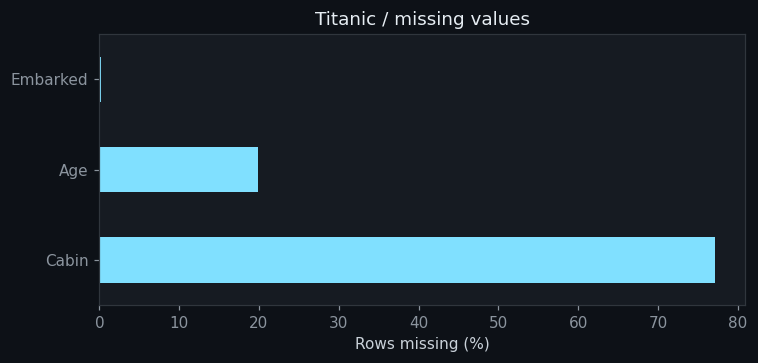

In [3]:
df = pd.read_csv(DATA / "titanic_dataset.csv")
print("Shape:", df.shape)
display(df.head())
display(df.dtypes.rename("dtype").to_frame())
display(df["Survived"].value_counts(normalize=True).rename("class share").to_frame())
missing = df.isna().mean().sort_values(ascending=False)
display((missing * 100).round(2).rename("missing %").to_frame())
summary["titanic_rows"] = len(df)
summary["titanic_survival_rate"] = float(df["Survived"].mean())
plt.figure(figsize=(7, 3.4))
missing[missing > 0].mul(100).plot.barh()
plt.xlabel("Rows missing (%)")
plt.title("Titanic / missing values")
plt.tight_layout()
save_plot("titanic_missingness.png")

## Part B / Features that exist before the outcome

Family size combines two counts; `IsAlone` flags a passenger travelling alone.
Title combines clues about sex, age, and social context. `log1p(Fare)` reduces
the effect of extreme fares and also accepts zero. These row-wise transformations
learn no population statistics, so they can be computed before splitting.
They must never use `Survived`.

,Name,Title,FamilySize,IsAlone,Fare,LogFare
0,"Braund, Mr. Owen Harris",Mr,2,0,7.2500,2.110213
1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",Mrs,2,0,71.2833,4.280593
2,"Heikkinen, Miss. Laina",Miss,1,1,7.9250,2.188856
3,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",Mrs,2,0,53.1000,3.990834
4,"Allen, Mr. William Henry",Mr,1,1,8.0500,2.202765


,count
Title,
Mr,517
Miss,182
Mrs,125
Master,40
Other,27


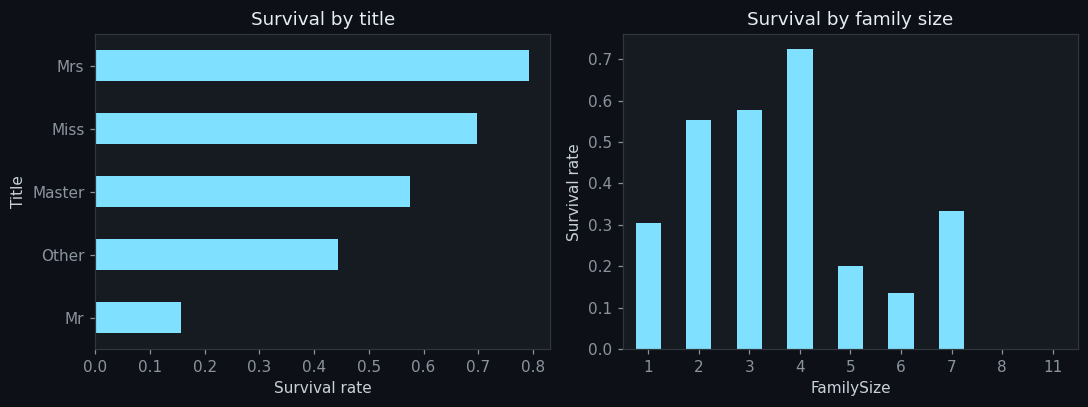

In [4]:
df["FamilySize"] = df["SibSp"] + df["Parch"] + 1
df["IsAlone"] = (df["FamilySize"] == 1).astype(int)
df["Title"] = df["Name"].str.extract(r",\s*([^\.]+)\.")[0].str.strip()
df["Title"] = df["Title"].where(df["Title"].isin(["Mr", "Mrs", "Miss", "Master"]), "Other")
df["LogFare"] = np.log1p(df["Fare"])
display(df[["Name", "Title", "FamilySize", "IsAlone", "Fare", "LogFare"]].head())
display(df["Title"].value_counts().to_frame())
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
df.groupby("Title")["Survived"].mean().sort_values().plot.barh(ax=axes[0])
axes[0].set(xlabel="Survival rate", title="Survival by title")
df.groupby("FamilySize")["Survived"].mean().plot.bar(ax=axes[1], rot=0)
axes[1].set(ylabel="Survival rate", title="Survival by family size")
plt.tight_layout()
save_plot("titanic_engineered_features.png")

In [5]:
# Split row indices once: all feature comparisons use exactly the same people.
train_idx, valid_idx = train_test_split(df.index, test_size=0.25,
                                      random_state=SEED, stratify=df["Survived"])
assert set(train_idx).isdisjoint(valid_idx)
feature_sets = {
    "raw columns": (["Age", "SibSp", "Parch", "Fare"], ["Pclass", "Sex", "Embarked"]),
    "raw + engineered": (["Age", "SibSp", "Parch", "LogFare", "FamilySize", "IsAlone"],
                         ["Pclass", "Sex", "Embarked", "Title"]),
}
feature_results = {}

def compare_features(name, num_cols, cat_cols):
    columns = num_cols + cat_cols
    model = Pipeline([
        ("preprocess", make_preprocess(num_cols, cat_cols)),
        ("model", LogisticRegression(max_iter=2000)),
    ])
    model.fit(df.loc[train_idx, columns], df.loc[train_idx, "Survived"])
    probability = model.predict_proba(df.loc[valid_idx, columns])[:, 1]
    feature_results[name] = float(roc_auc_score(df.loc[valid_idx, "Survived"], probability))

for name, (num_cols, cat_cols) in feature_sets.items():
    compare_features(name, num_cols, cat_cols)
display(pd.Series(feature_results, name="validation ROC AUC").to_frame().round(4))

,validation ROC AUC
raw columns,0.8421
raw + engineered,0.8723


### Try it yourself / Cabin deck and fare per family member

Use the cabin's first letter, with `Unknown` for missing cabin information,
and divide fare by family size. Compare each addition and both together on
the same split and estimator. Validation selects features; these values are
exploratory comparisons, not an independent final test.

,validation_roc_auc
raw columns,0.8421
raw + engineered,0.8723
engineered + cabin,0.8677
engineered + fare/family,0.8721
engineered + both,0.8679


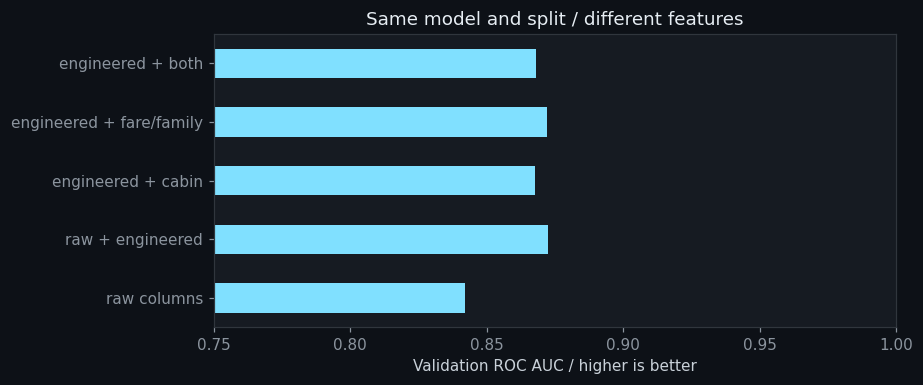

In [6]:
df["CabinInitial"] = df["Cabin"].fillna("Unknown").str[0]
df["FarePerFamily"] = df["Fare"] / df["FamilySize"]
num, cat = feature_sets["raw + engineered"]
compare_features("engineered + cabin", num, cat + ["CabinInitial"])
compare_features("engineered + fare/family", num + ["FarePerFamily"], cat)
compare_features("engineered + both", num + ["FarePerFamily"], cat + ["CabinInitial"])
feature_table = pd.Series(feature_results, name="validation_roc_auc").to_frame()
display(feature_table.round(4))
feature_table.to_csv(OUT / "feature_comparison.csv", index_label="features")
summary["feature_auc"] = feature_results
plt.figure(figsize=(8.5, 3.6))
feature_table["validation_roc_auc"].plot.barh()
plt.xlim(0.75, 1.0)
plt.xlabel("Validation ROC AUC / higher is better")
plt.title("Same model and split / different features")
plt.tight_layout()
save_plot("titanic_feature_comparison.png")

## Part C / Scaling changes distance

Area and smoothness use very different units. Raw Euclidean distance can be
dominated by large-unit columns. Standardization centers each measurement
and divides by its standard deviation. This is a descriptive geometry demo
on all rows; a predictive evaluation would fit the scaler on training rows.

,area_mean,texture_mean,smoothness_mean
mean,654.8891,19.2896,0.0964
std,351.9141,4.3010,0.0141


Closest tumour pair (numbered 1-5): {'raw': [3, 5], 'standardized': [2, 5]}


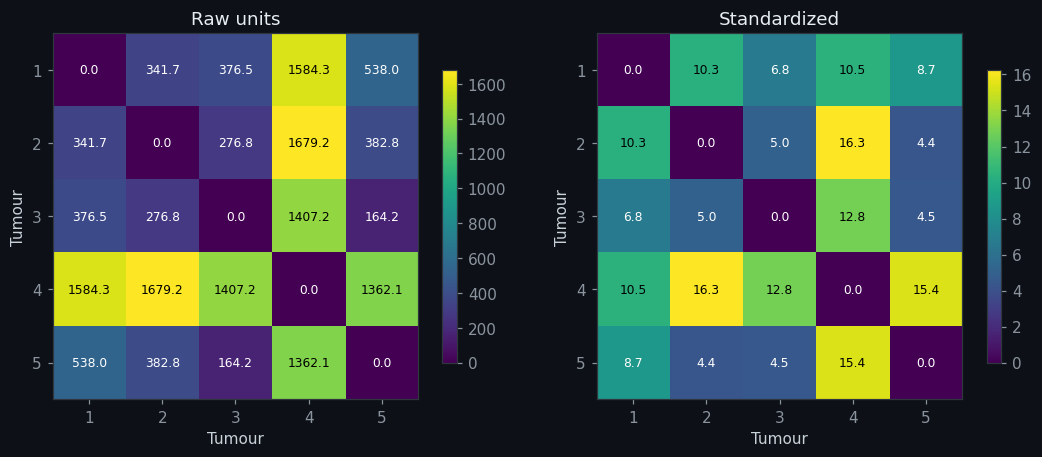

In [7]:
cancer = pd.read_csv(DATA / "breast_cancer_dataset.csv")
X_cancer = cancer.drop(columns=["id", "diagnosis", "Unnamed: 32"], errors="ignore")
display(X_cancer[["area_mean", "texture_mean", "smoothness_mean"]].describe().loc[["mean", "std"]].round(4))
raw = pairwise_distances(X_cancer.iloc[:5])
scaled_features = StandardScaler().fit_transform(X_cancer)
scaled = pairwise_distances(scaled_features[:5])

def closest_pair(matrix):
    i, j = np.triu_indices_from(matrix, k=1)
    k = matrix[i, j].argmin()
    return [int(i[k] + 1), int(j[k] + 1)]

summary["closest_tumours"] = {"raw": closest_pair(raw), "standardized": closest_pair(scaled)}
print("Closest tumour pair (numbered 1-5):", summary["closest_tumours"])
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, matrix, title in [(axes[0], raw, "Raw units"), (axes[1], scaled, "Standardized")]:
    image = ax.imshow(matrix, cmap="viridis")
    ax.set(xticks=range(5), yticks=range(5), xticklabels=range(1, 6), yticklabels=range(1, 6),
           xlabel="Tumour", ylabel="Tumour", title=title)
    for i in range(5):
        for j in range(5):
            color = "black" if matrix[i, j] > matrix.max() * 0.6 else "white"
            ax.text(j, i, f"{matrix[i, j]:.1f}", ha="center", va="center", color=color, fontsize=8)
    fig.colorbar(image, ax=ax, shrink=0.8)
plt.tight_layout()
save_plot("scaling_geometry.png")

## Part D / Feature selection without leakage

Predict final grade `G3`. The handout removes `G1` and `G2` for an
enrolment-time forecast. We reproduce its 30-column comparison, fit feature
selection only inside training pipelines, and deliberately add `G2` once
to show why a lower error can be misleading.

**Timing caveat:** `absences` is usually accumulated during the school year,
so its availability at enrolment is doubtful. A stricter comparison below
also removes it. Other questionnaire fields require a timing check in a
real enrolment deployment; the supplied CSV does not timestamp them.

In [8]:
students = pd.read_csv(DATA / "student_performance_dataset.csv")
print("Shape:", students.shape, "Missing:", int(students.isna().sum().sum()),
      "Duplicates:", int(students.duplicated().sum()))
X_s = students.drop(columns=["G3", "G1", "G2"])
y_s = students["G3"]
s_num = X_s.select_dtypes(include="number").columns.tolist()
s_cat = X_s.select_dtypes(exclude="number").columns.tolist()
print(len(s_num), "numeric +", len(s_cat), "categorical candidates")
assert X_s.shape[1] == 30
Xs_train, Xs_valid, ys_train, ys_valid = train_test_split(X_s, y_s, test_size=0.25, random_state=SEED)
student_results = {}

def evaluate_student(pipeline, X_train, X_valid, label):
    pipeline.fit(X_train, ys_train)
    mae = float(mean_absolute_error(ys_valid, pipeline.predict(X_valid)))
    student_results[label] = mae
    print(f"{label:34s} MAE = {mae:.3f} grade points")
    return pipeline

evaluate_student(Pipeline([("preprocess", make_preprocess(s_num, s_cat)),
                           ("model", Ridge(alpha=1.0))]), Xs_train, Xs_valid, "all 30 features")
selected_models = {}
for k in [5, 10, 20]:
    selected_models[k] = evaluate_student(Pipeline([
        ("preprocess", make_preprocess(s_num, s_cat)),
        ("select", SelectKBest(f_regression, k=k)),
        ("model", Ridge(alpha=1.0)),
    ]), Xs_train, Xs_valid, f"SelectKBest k={k}")
lasso = evaluate_student(Pipeline([
    ("preprocess", make_preprocess(s_num, s_cat)),
    ("model", Lasso(alpha=0.1, max_iter=10000)),
]), Xs_train, Xs_valid, "lasso")
evaluate_student(Pipeline([
    ("preprocess", make_preprocess(s_num + ["G2"], s_cat)),
    ("model", Ridge(alpha=1.0)),
]), Xs_train.assign(G2=students.loc[Xs_train.index, "G2"]),
    Xs_valid.assign(G2=students.loc[Xs_valid.index, "G2"]), "all 30 + G2 (leakage demo)")
strict_num = [c for c in s_num if c != "absences"]
evaluate_student(Pipeline([
    ("preprocess", make_preprocess(strict_num, s_cat)),
    ("model", Ridge(alpha=1.0)),
]), Xs_train.drop(columns="absences"), Xs_valid.drop(columns="absences"), "also exclude absences")
student_table = pd.Series(student_results, name="validation_mae").to_frame()
display(student_table.round(4))
student_table.to_csv(OUT / "student_feature_selection.csv", index_label="model")
summary["student_mae"] = student_results

Shape: (649, 33) Missing: 0 Duplicates: 0
13 numeric + 17 categorical candidates
all 30 features                    MAE = 2.181 grade points
SelectKBest k=5                    MAE = 2.134 grade points
SelectKBest k=10                   MAE = 2.139 grade points
SelectKBest k=20                   MAE = 2.125 grade points
lasso                              MAE = 2.077 grade points


all 30 + G2 (leakage demo)         MAE = 0.762 grade points
also exclude absences              MAE = 2.185 grade points


,validation_mae
all 30 features,2.1806
SelectKBest k=5,2.1338
SelectKBest k=10,2.1385
SelectKBest k=20,2.1246
lasso,2.0773
all 30 + G2 (leakage demo),0.7619
also exclude absences,2.1848


Lasso retained 18 of 56 encoded columns


,coefficient
num__failures,-0.9416
cat__higher_no,-0.7922
num__Dalc,-0.3492
cat__reason_other,-0.2290
num__health,-0.1849
num__freetime,-0.0240
num__goout,-0.0143
num__absences,-0.0135
num__traveltime,-0.0079
cat__school_MS,-0.0000


SelectKBest k=10 retained: ['num__Medu', 'num__studytime', 'num__failures', 'num__Dalc', 'cat__school_GP', 'cat__school_MS', 'cat__reason_other', 'cat__reason_reputation', 'cat__higher_no', 'cat__higher_yes']


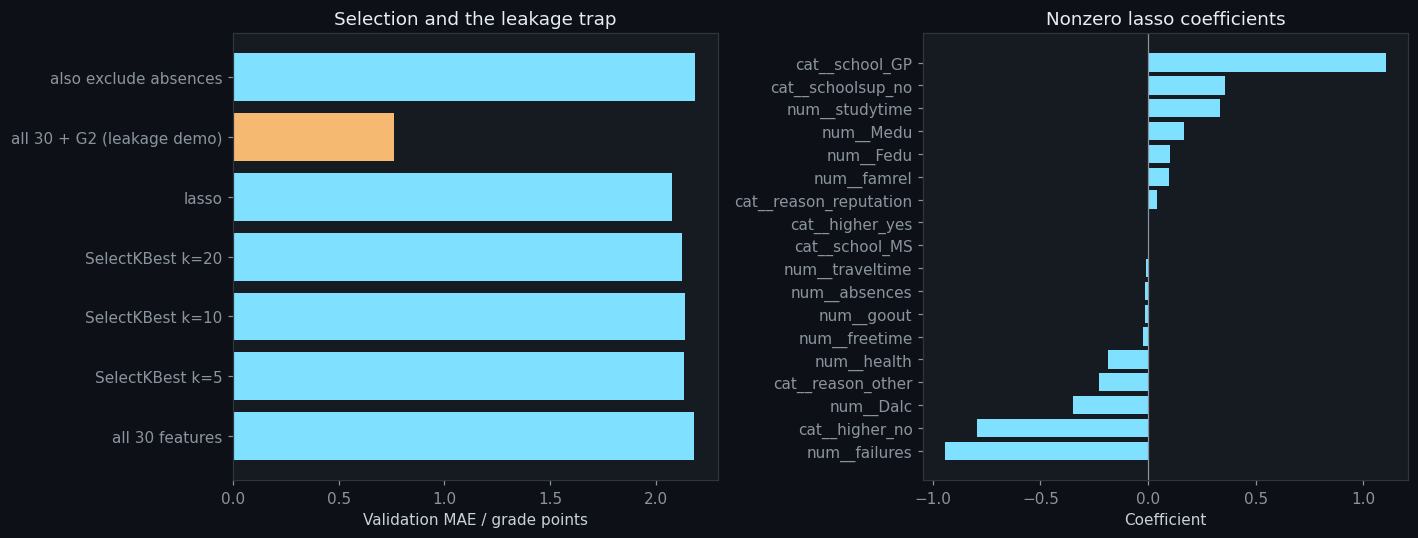

983

In [9]:
coefs = pd.Series(lasso.named_steps["model"].coef_,
                  index=lasso.named_steps["preprocess"].get_feature_names_out())
kept = coefs[coefs != 0].sort_values()
print(f"Lasso retained {len(kept)} of {len(coefs)} encoded columns")
display(kept.rename("coefficient").to_frame().round(4))
selector = selected_models[10]
names = selector.named_steps["preprocess"].get_feature_names_out()
print("SelectKBest k=10 retained:", names[selector.named_steps["select"].get_support()].tolist())
summary["lasso_encoded_columns"] = len(coefs)
summary["lasso_retained"] = len(kept)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
colors = ["#f5b971" if "leakage" in label else "#80e0ff" for label in student_results]
axes[0].barh(list(student_results), list(student_results.values()), color=colors)
axes[0].set(xlabel="Validation MAE / grade points", title="Selection and the leakage trap")
axes[1].barh(kept.index, kept.values)
axes[1].axvline(0, color="#8b949e", linewidth=0.8)
axes[1].set(title="Nonzero lasso coefficients", xlabel="Coefficient")
plt.tight_layout()
save_plot("student_selection.png")
(OUT / "summary.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")

## Check your understanding / Worked answers

1. **Why split before learned preprocessing?** A median, mean, scale,
   selected feature, or encoded vocabulary estimated using validation/test
   rows gives training access to information it should not have. Split first;
   fit each transformer only on training rows. A pipeline also refits these
   transformers within each cross-validation training fold.
2. **Identifier, feature, label?** An identifier locates a row, such as
   `PassengerId`. A feature is an input available at prediction time, such
   as age or ticket class. A label is the answer being learned, such as
   survival or `G3`. IDs rarely provide a transferable relationship and can
   encourage memorization.
3. **Why define the prediction moment?** `G2` is unavailable at enrolment,
   but can be a legitimate input when forecasting `G3` after period 2.
   Leakage is relative to what would really be known then. The same check
   applies to accumulated absences.

The feature and selection tables show the results of both extensions. A
better validation score is evidence for this split, not proof of a causal
relationship or a guaranteed improvement on future students/passengers.